# FireRisk AI — Etapa 3: otimização e IA responsável

Nesta etapa, o modelo **LightGBM** selecionado na Etapa 2 é otimizado e analisado em termos de explicabilidade e possíveis diferenças de desempenho entre grupos geográficos.

Objetivos:

- otimizar hiperparâmetros com **Optuna**;
- manter o conjunto de teste fora da otimização;
- escolher o threshold operacional na validação;
- usar **SHAP** para identificar as variáveis mais importantes;
- avaliar diferenças de desempenho por **região** e **UF**;
- documentar limitações e recomendações de IA responsável.

A execução principal e reprodutível está em `src/otimizacao_explicabilidade_etapa3.py`. O notebook abaixo lê os resultados já executados para evitar repetir a otimização toda vez que for aberto.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('..')
if not (ROOT / 'reports').exists():
    ROOT = Path('.')

ETAPA3 = ROOT / 'reports' / 'etapa3'
FIGURES = ROOT / 'reports' / 'figures'


## 1. Como reproduzir a otimização

A otimização foi executada com Optuna usando validação temporal interna somente dentro do período de treino. O conjunto de teste não foi usado para escolher os hiperparâmetros nem o threshold.

Para repetir a execução completa, rode na raiz do repositório:

```bash
python src/otimizacao_explicabilidade_etapa3.py
```

A execução entregue utilizou **6 trials**, suficientes para demonstrar a pipeline completa. O script pode ser configurado com mais trials para uma busca mais ampla.

In [2]:
trials = pd.read_csv(ETAPA3 / 'optuna_trials.csv')
best = json.loads((ETAPA3 / 'optuna_best_params.json').read_text(encoding='utf-8'))

print('Número de trials executados:', best['n_trials'])
print('Melhor ROC-AUC médio na CV temporal:', round(best['best_cv_roc_auc'], 4))
print('Melhores hiperparâmetros:')
for k, v in best['params'].items():
    print(f'  {k}: {v}')

trials[['number', 'value', 'state']].head(10)


Número de trials executados: 6
Melhor ROC-AUC médio na CV temporal: 0.8135
Melhores hiperparâmetros:
  n_estimators: 100
  learning_rate: 0.076070187687831
  num_leaves: 49
  max_depth: 4
  min_child_samples: 25
  subsample: 0.7958511274633584
  colsample_bytree: 0.8260605607398844
  reg_alpha: 0.0180714563413956
  reg_lambda: 0.007207895500630222
  scale_pos_weight: 2.1649165607921677


,number,value,state
0,0,0.807233,COMPLETE
1,1,0.813546,COMPLETE
2,2,0.813348,COMPLETE
3,3,0.813103,COMPLETE
4,4,0.810322,COMPLETE
5,5,0.806617,COMPLETE


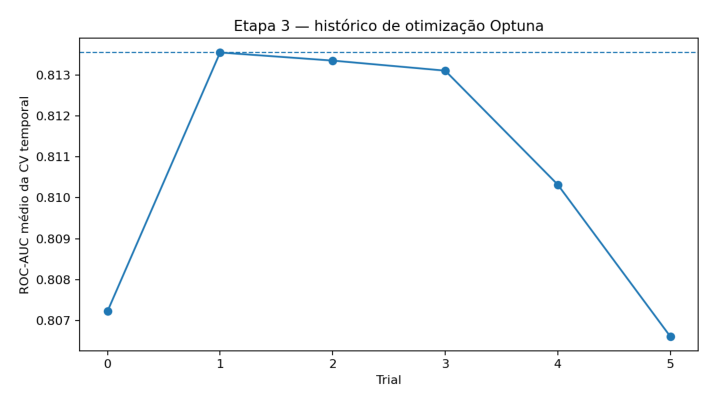

In [3]:
img = plt.imread(FIGURES / 'etapa3_optuna_historico.png')
plt.figure(figsize=(10,5))
plt.imshow(img)
plt.axis('off')
plt.show()


## 2. Comparação antes e depois do Optuna

A comparação usa o mesmo conjunto de teste temporal. O threshold da Etapa 3 foi escolhido apenas no conjunto de validação, com prioridade para atender as metas de negócio de recall e precision.

In [4]:
comparacao = pd.read_csv(ETAPA3 / 'comparacao_etapa2_etapa3.csv')
comparacao


,modelo,threshold,acuracia,precisao,recall,f1_score,roc_auc,false_negative_rate,TN,FP,FN,TP
0,LightGBM Etapa 2,0.42,0.750505,0.349353,0.701299,0.466379,0.809189,0.298701,2224,704,161,378
1,LightGBM + Optuna Etapa 3,0.34,0.758004,0.360075,0.716141,0.479205,0.817627,0.283859,2242,686,153,386


### Resultado

Após a otimização, o modelo apresentou:

- **Recall:** 0.716
- **Precision:** 0.360
- **F1-score:** 0.479
- **ROC-AUC:** 0.818
- **False Negative Rate:** 0.284
- **Threshold operacional:** 0.34

O modelo otimizado melhorou o F1, ROC-AUC e recall em relação à versão da Etapa 2.

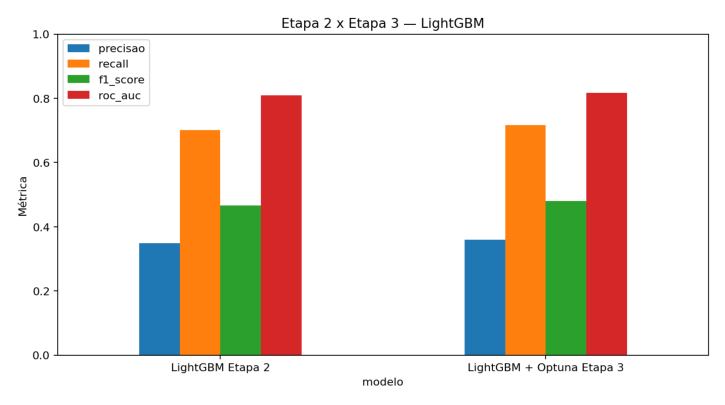

In [5]:
img = plt.imread(FIGURES / 'etapa3_comparacao_modelo.png')
plt.figure(figsize=(10,5))
plt.imshow(img)
plt.axis('off')
plt.show()


## 3. Explicabilidade com SHAP

O SHAP foi aplicado ao LightGBM para medir a contribuição das variáveis para as predições. Para variáveis categóricas codificadas por one-hot, as importâncias foram agregadas de volta para a variável original.

**Importante:** importância SHAP não prova causalidade. Ela mostra quanto uma variável influencia as predições do modelo dentro dos dados analisados.

In [6]:
shap_imp = pd.read_csv(ETAPA3 / 'shap_importancia_variaveis.csv')
shap_imp.head(15)


,variavel_original,mean_abs_shap,participacao_pct
0,mb_log_total_area,0.640913,20.290483
1,temperatura_maxima,0.455134,14.408971
2,radiacao_global_diaria,0.308990,9.782239
3,umidade_media,0.248595,7.870193
4,temperatura_media,0.143093,4.530152
5,precipitacao_diaria,0.118940,3.765496
6,latitude,0.112912,3.574646
7,mb_share_afloramento_rochoso,0.108951,3.449236
8,mb_share_cana,0.088556,2.803554
9,longitude,0.069675,2.205823


### As 3 variáveis com maior peso global

1. **mb_log_total_area** — 20.3% da importância SHAP agregada;
2. **temperatura_maxima** — 14.4%;
3. **radiacao_global_diaria** — 9.8%.

O resultado mostra que o modelo usa uma combinação de características estruturais do município e condições meteorológicas. Isso é coerente com a proposta do projeto, mas reforça a necessidade de monitorar se o modelo passa a depender excessivamente de atributos fixos de localização.

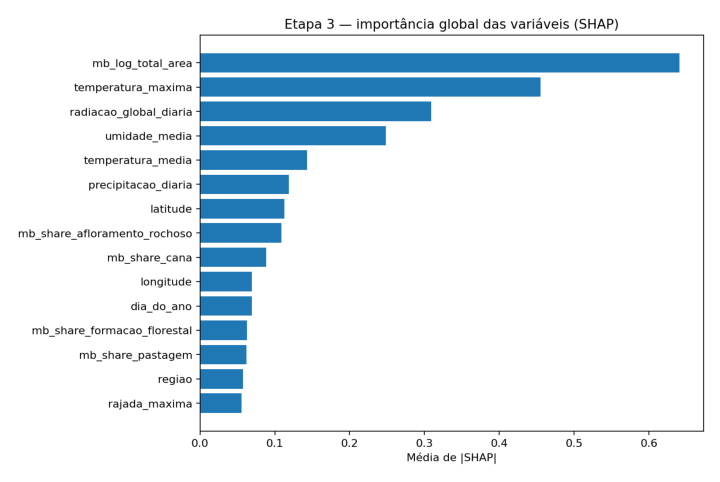

In [7]:
img = plt.imread(FIGURES / 'etapa3_shap_top15.png')
plt.figure(figsize=(10,6))
plt.imshow(img)
plt.axis('off')
plt.show()


## 4. Análise de viés / desempenho desigual

A base não contém gênero, raça ou outros atributos demográficos. Portanto, não é possível testar esses tipos de viés com os dados disponíveis.

A análise possível foi geográfica, comparando o desempenho por região e UF. Para UF, foi usado um mínimo de observações e positivos para reduzir conclusões instáveis causadas por grupos muito pequenos.

In [8]:
bias_regiao = pd.read_csv(ETAPA3 / 'analise_vies_regiao.csv')
bias_regiao


,regiao,n,positivos_reais,taxa_real_positiva,taxa_alerta_modelo,precisao,recall,f1_score,roc_auc,false_negative_rate,TP,FP,FN,TN
0,Centro-Oeste,577.0,107.0,0.185442,0.450607,0.353846,0.859813,0.501362,0.837502,0.140187,92.0,168.0,15.0,302.0
1,Norte,488.0,75.0,0.153689,0.342213,0.353293,0.786667,0.487603,0.844536,0.213333,59.0,108.0,16.0,305.0
2,Nordeste,745.0,157.0,0.210738,0.446980,0.339339,0.719745,0.461224,0.748873,0.280255,113.0,220.0,44.0,368.0
3,Sul,642.0,74.0,0.115265,0.177570,0.403509,0.621622,0.489362,0.850150,0.378378,46.0,68.0,28.0,500.0
4,Sudeste,1015.0,126.0,0.124138,0.195074,0.383838,0.603175,0.469136,0.822701,0.396825,76.0,122.0,50.0,767.0


### Resultado por região

O gap de recall entre as regiões analisadas foi de aproximadamente **0.257**.

- maior recall: **Centro-Oeste**;
- menor recall: **Sudeste**.

Essa diferença é relevante e deve ser monitorada. Ela não demonstra, sozinha, um viés injusto, pois também pode refletir diferenças na frequência de queimadas, clima, cobertura do solo e tamanho da amostra entre as regiões.

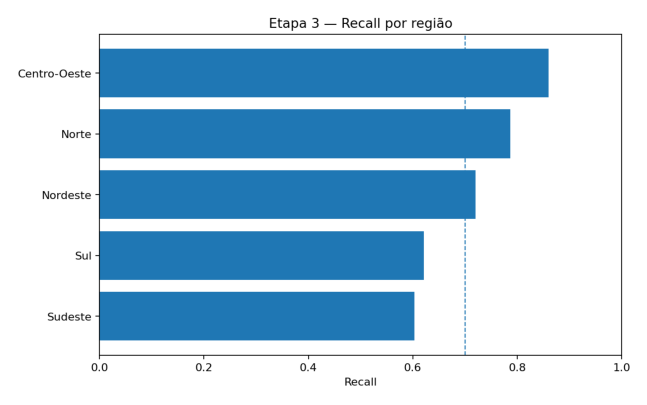

In [9]:
img = plt.imread(FIGURES / 'etapa3_recall_regiao.png')
plt.figure(figsize=(9,5))
plt.imshow(img)
plt.axis('off')
plt.show()


In [10]:
bias_uf = pd.read_csv(ETAPA3 / 'analise_vies_uf.csv')
bias_uf[bias_uf['elegivel_comparacao']].sort_values('recall')


,sigla_uf,n,positivos_reais,taxa_real_positiva,taxa_alerta_modelo,precisao,recall,f1_score,roc_auc,false_negative_rate,TP,FP,FN,TN,elegivel_comparacao
15,PR,172.0,11.0,0.063953,0.017442,0.333333,0.090909,0.142857,0.782609,0.909091,1.0,2.0,10.0,159.0,True
14,SC,153.0,10.0,0.065359,0.111111,0.294118,0.500000,0.370370,0.900699,0.500000,5.0,12.0,5.0,131.0,True
13,MG,513.0,64.0,0.124756,0.243665,0.288000,0.562500,0.380952,0.780102,0.437500,36.0,89.0,28.0,360.0,True
11,RJ,160.0,25.0,0.156250,0.193750,0.483871,0.600000,0.535714,0.827259,0.400000,15.0,16.0,10.0,119.0,True
12,SP,254.0,20.0,0.078740,0.094488,0.500000,0.600000,0.545455,0.867735,0.400000,12.0,12.0,8.0,222.0,True
10,BA,216.0,61.0,0.282407,0.453704,0.428571,0.688525,0.528302,0.790851,0.311475,42.0,56.0,19.0,99.0,True
9,RS,317.0,53.0,0.167192,0.296530,0.425532,0.754717,0.544218,0.829367,0.245283,40.0,54.0,13.0,210.0,True
8,PI,105.0,33.0,0.314286,0.619048,0.384615,0.757576,0.510204,0.594276,0.242424,25.0,40.0,8.0,32.0,True
7,ES,88.0,17.0,0.193182,0.204545,0.722222,0.764706,0.742857,0.877382,0.235294,13.0,5.0,4.0,66.0,True
6,TO,136.0,30.0,0.220588,0.308824,0.547619,0.766667,0.638889,0.883333,0.233333,23.0,19.0,7.0,87.0,True


## 5. Recomendações de IA responsável

Antes de uma aplicação operacional, eu recomendo:

- ampliar o período histórico, porque o projeto atual cobre apenas 43 dias;
- acompanhar Recall e False Negative Rate separadamente por região e UF;
- monitorar *data drift* e *concept drift*;
- manter o threshold como parâmetro de negócio e revisá-lo com custos reais;
- evitar interpretar SHAP como causalidade;
- executar o teste A/B planejado na Etapa 2 antes de uma implantação definitiva;
- definir responsáveis por revisar alertas e por interromper o modelo caso o desempenho caia.


## 6. Conclusão da Etapa 3

A otimização com Optuna melhorou o LightGBM em relação à versão da Etapa 2. No conjunto de teste, o modelo final de avaliação alcançou **ROC-AUC de 0.818**, **F1 de 0.479** e **Recall de 0.716**, mantendo o FNR abaixo de 0,30.

O SHAP mostrou que as variáveis de maior peso foram **mb_log_total_area**, **temperatura_maxima** e **radiacao_global_diaria**.

A análise geográfica mostrou diferenças de desempenho entre regiões, indicando que o modelo precisa de monitoramento segmentado. Como a janela temporal ainda é curta, o resultado deve ser visto como uma prova de conceito sólida e não como um modelo pronto para decisões críticas sem validação adicional.

O projeto agora possui uma pipeline completa de preparação, EDA, comparação de modelos, cálculo de impacto, teste A/B planejado, otimização, explicabilidade e análise de desempenho por grupos.